# TP7 — Détection d'objets avec YOLO

Notebook complété. Les cellules d'expérience calculent les mesures et produisent les figures à l'exécution. Pour les neuf entraînements, utiliser de préférence un environnement Colab muni d'un GPU et exécuter les cellules dans l'ordre.

Dans le TP précédent, vous avez fait de la **classification** : *une image → une étiquette*. Ici on passe à la **détection d'objets** : *une image → une liste de boîtes*, chacune avec une classe et un score de confiance.

On utilise **YOLO** (*You Only Look Once*), un détecteur qui prédit toutes les boîtes en **une seule passe** dans le réseau, via la bibliothèque **Ultralytics** (PyTorch).

**Objectifs**
1. Comprendre comment on représente une détection (boîtes, formats, **IoU**)
2. Utiliser un YOLO **pré-entraîné sur COCO** (80 classes) et analyser ses sorties
3. Comprendre le post-traitement : seuil de confiance et **NMS** (que vous coderez)
4. **Fine-tuner** YOLO sur un nouveau jeu de données
5. **Évaluer** un détecteur : précision, rappel, **mAP**, et analyser ses erreurs

**Données :** COCO (pré-entraînement) puis `african-wildlife` : environ 1 500 photos annotées, 4 classes (buffle, éléphant, rhinocéros, zèbre), téléchargé automatiquement.

⚙️ Sur Colab, activez le GPU : *Exécution → Modifier le type d'exécution → GPU*.

## 1. Un détecteur pré-entraîné

In [24]:
%pip install -q ultralytics

In [25]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import torch
import ultralytics
from ultralytics import YOLO
from ultralytics.utils import ASSETS

print("Ultralytics", ultralytics.__version__, "| GPU :", torch.cuda.is_available())

model = YOLO("yolo11n.pt")          # n = nano, la plus petite version, pré-entraînée sur COCO
model.info()
print(len(model.names), "classes :", list(model.names.values())[:12], "...")

Ultralytics 8.4.216 | GPU : True
YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs
80 classes : ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign'] ...



image 1/1 /usr/local/lib/python3.13/dist-packages/ultralytics/assets/bus.jpg: 640x480 4 persons, 1 bus, 8.3ms
Speed: 2.0ms preprocess, 8.3ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 480)


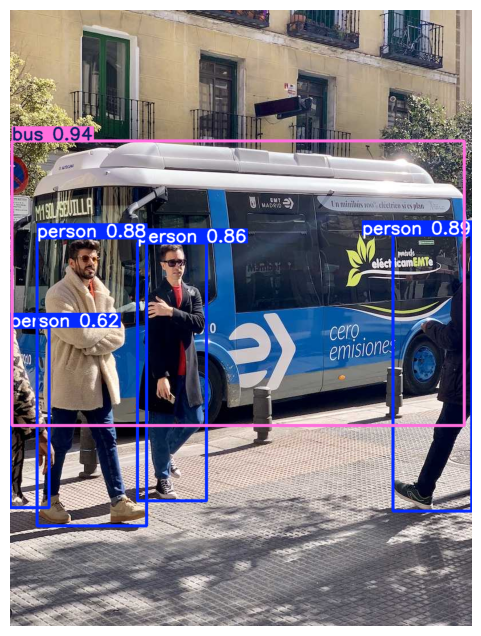

In [26]:
res = model(ASSETS / "bus.jpg")[0]           # une image en entrée → un objet Results

plt.figure(figsize=(6, 8))
plt.imshow(res.plot()[..., ::-1])            # plot() renvoie une image BGR (OpenCV) → on inverse les canaux
plt.axis("off"); plt.show()

Chaque détection est une **boîte**, une **classe** et une **confiance**. Les boîtes sont disponibles dans plusieurs formats :

In [ ]:
b = res.boxes
print("Taille de l'image :", res.orig_shape, "(h, w)")
print("Nombre de détections :", len(b))
print("xyxy  (x1, y1, x2, y2) en pixels :\n", b.xyxy.round())
print("xywhn (cx, cy, w, h) normalisés :\n", b.xywhn.round(decimals=3))
print("classes :", [model.names[int(c)] for c in b.cls])
print("conf    :", b.conf.round(decimals=2))
print("Temps (ms) :", {k: round(v, 1) for k, v in res.speed.items()})

**Question 1 :** En classification, la sortie du réseau était un vecteur de taille fixe (5 probabilités). Ici, quelle est la forme de la sortie ? Pourquoi le nombre de détections est-il **variable**, et quelles difficultés cela pose-t-il (pour l'architecture, pour la fonction de perte, pour l'évaluation) ?

**Question 2 :** Combien de paramètres a YOLO11n ? Comparez avec EfficientNetB0 (TP6) et votre AlexNet. Combien de millisecondes prend une inférence, et combien d'images par seconde cela représente-t-il ? Pourquoi dit-on que YOLO est un détecteur « temps réel » ?

**1.** Après filtrage, la sortie a la forme N × 6 (quatre coordonnées, score et classe). N peut être nul et dépend du contenu de l'image, du seuil et de la NMS. La tête prédit un ensemble dense de candidats de taille fixe pour une résolution donnée. À l'entraînement, il faut assigner des candidats aux objets annotés et combiner classification et régression. À l'évaluation, un appariement un-à-un par classe et IoU empêche de compter plusieurs fois le même objet.

**2.** Ultralytics annonce environ 2,6 M de paramètres pour YOLO11n COCO. EfficientNetB0 standard avec tête ImageNet en a environ 5,3 M (environ 4 M sans la tête), contre environ 61 M pour AlexNet standard. Les comptes du TP6 dépendent des têtes personnalisées et de l'architecture exacte. La cellule suivante mesure la latence après échauffement et calcule 1 000 / latence en ms. La passe unique du réseau permet le traitement en temps réel si le débit de bout en bout suit la fréquence de la caméra.

[Ultralytics YOLO11](https://docs.ultralytics.com/models/yolo11) · [EfficientNet](https://proceedings.mlr.press/v97/tan19a.html) · [AlexNet](https://proceedings.neurips.cc/paper/2012/hash/c399862d3b9d6b76c8436e924a68c45b-Abstract.html)

In [23]:
mesures = []
for essai in range(11):
    prediction = model(ASSETS / "bus.jpg", verbose=False)[0]
    if essai:
        mesures.append([prediction.speed[k] for k in ("preprocess", "inference", "postprocess")])
latence = np.asarray(mesures)
mediane = np.median(latence[:, 1])
total = np.median(latence.sum(axis=1))
print(f"YOLO11n COCO : {sum(p.numel() for p in model.model.parameters()):,} paramètres")
print(f"Inférence médiane : {mediane:.2f} ms ({1000 / mediane:.1f} images/s)")
print(f"Préparation + inférence + post-traitement : {total:.2f} ms ({1000 / total:.1f} images/s), hors lecture d'image")

YOLO11n COCO : 2,624,080 paramètres
Inférence médiane : 8.23 ms (121.6 images/s)
Préparation + inférence + post-traitement : 11.06 ms (90.4 images/s), hors lecture d'image


## 2. Boîtes englobantes et IoU

Une boîte peut s'écrire :
- `xyxy` : coins haut-gauche et bas-droit, en pixels ;
- `xywh` : centre, largeur, hauteur, en pixels ;
- `xywhn` : idem mais **normalisé** entre 0 et 1 par la taille de l'image. C'est le format des fichiers d'annotation YOLO.

Pour comparer deux boîtes, on utilise l'**IoU** (*Intersection over Union*) :

$$\text{IoU}(A, B) = \frac{\text{aire}(A \cap B)}{\text{aire}(A \cup B)} \in [0, 1]$$

L'IoU est utilisée partout : pour supprimer les doublons (NMS), pour apparier prédictions et vérité terrain pendant l'entraînement, et pour l'évaluation (une détection est correcte si son IoU avec une boîte réelle dépasse un seuil, souvent 0,5).

In [27]:
def iou(a, b):
    # IoU entre une boîte a (4,) et N boîtes b (N, 4), format xyxy
    x1 = np.maximum(a[0], b[:, 0]); y1 = np.maximum(a[1], b[:, 1])
    x2 = np.minimum(a[2], b[:, 2]); y2 = np.minimum(a[3], b[:, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    aire = lambda r: (r[..., 2] - r[..., 0]) * (r[..., 3] - r[..., 1])
    return inter / (aire(a) + aire(b) - inter)

# Vérification avec torchvision
from torchvision.ops import box_iou
A, B = np.array([0, 0, 10, 10.]), np.array([[5, 5, 15, 15.], [0, 0, 10, 5], [20, 20, 30, 30]])
print("notre IoU   :", iou(A, B).round(3))
print("torchvision :", box_iou(torch.tensor(A[None]), torch.tensor(B))[0].numpy().round(3))

notre IoU   : [      0.143         0.5           0]
torchvision : [      0.143         0.5           0]


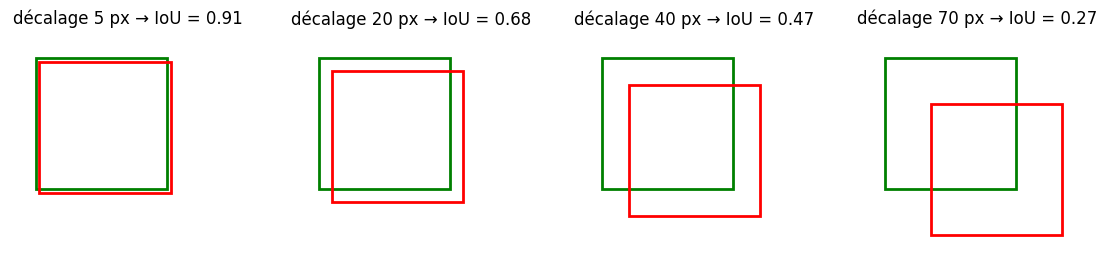

In [28]:
ref = np.array([100, 100, 300, 300])          # boîte 200 × 200
fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
for a, d in zip(ax, [5, 20, 40, 70]):
    autre = ref + d                            # même boîte décalée de d pixels en x et en y
    a.add_patch(patches.Rectangle(ref[:2], 200, 200, fill=False, ec="green", lw=2))
    a.add_patch(patches.Rectangle(autre[:2], 200, 200, fill=False, ec="red", lw=2))
    a.set_xlim(60, 420); a.set_ylim(420, 60); a.set_aspect("equal"); a.axis("off")
    a.set_title(f"décalage {d} px → IoU = {iou(ref, autre[None])[0]:.2f}")
plt.show()

**Question 3 :** Une boîte décalée de seulement 10 % de sa taille (20 px sur 200) dans les deux directions a une IoU de combien ? Le seuil « IoU ≥ 0,5 » est-il aussi permissif qu'il en a l'air ? La métrique **mAP50-95** fait la moyenne sur les seuils 0,50, 0,55, …, 0,95 : qu'est-ce qu'elle récompense en plus de mAP50 ?

**3.** L'intersection vaut 180² = 32 400 et l'union vaut 2 × 200² − 32 400 = 47 600, d'où une IoU de **0,681**. Deux carrés identiques décalés de plus d'environ 36,7 px sur les deux axes passent déjà sous 0,5. La mAP50–95 récompense une localisation plus précise en exigeant parfois jusqu'à 0,95 d'IoU.

## 3. Post-traitement : seuil de confiance et NMS

Pour une image 640×640, YOLO11 prédit une boîte candidate en chaque case de trois grilles (80×80, 40×40 et 20×20), soit **8 400 boîtes**. Deux filtres réduisent cette liste :
1. **Seuil de confiance** (`conf`, défaut 0,25) : on jette les boîtes peu sûres ;
2. **NMS** (*Non-Maximum Suppression*, seuil `iou`, défaut 0,7) : parmi des boîtes de même classe qui se chevauchent trop, on ne garde que la plus confiante.

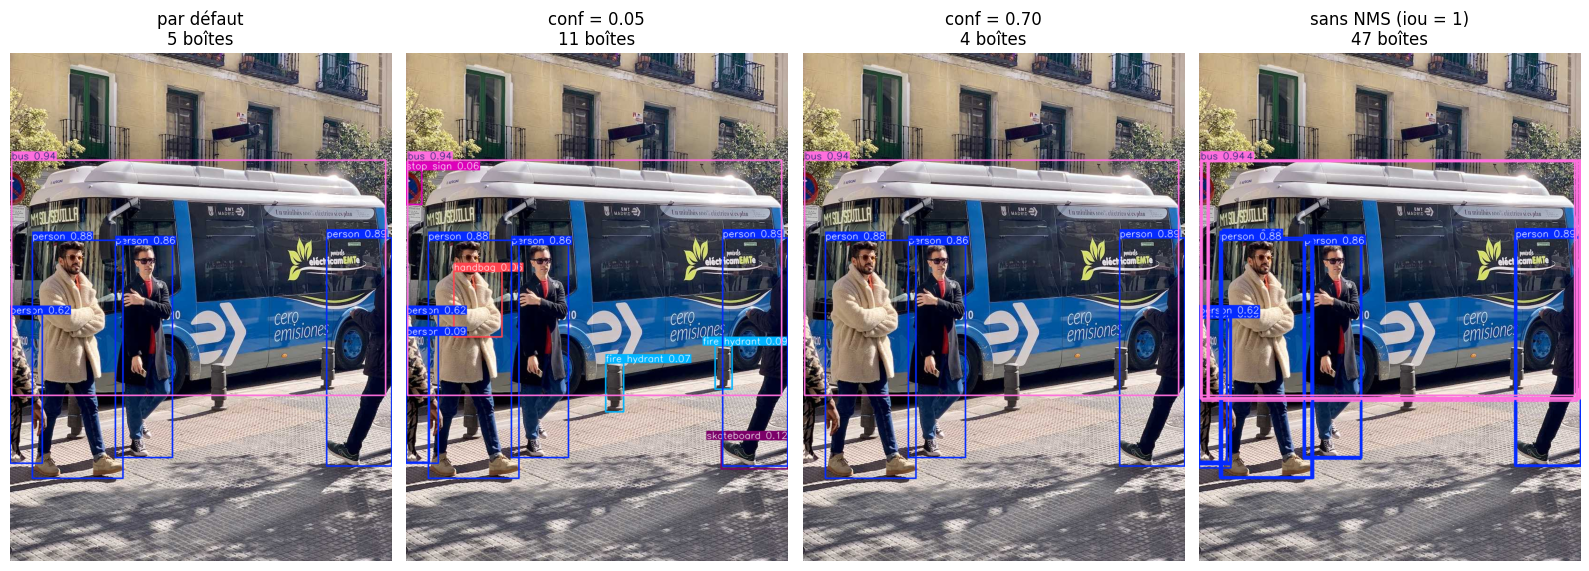

In [29]:
reglages = [(0.25, 0.7, "par défaut"), (0.05, 0.7, "conf = 0.05"),
            (0.70, 0.7, "conf = 0.70"), (0.25, 1.0, "sans NMS (iou = 1)")]
plt.figure(figsize=(16, 6))
for k, (conf, seuil_iou, titre) in enumerate(reglages):
    r = model(ASSETS / "bus.jpg", conf=conf, iou=seuil_iou, verbose=False)[0]
    plt.subplot(1, 4, k + 1)
    plt.imshow(r.plot(line_width=2, font_size=8)[..., ::-1]); plt.axis("off")
    plt.title(f"{titre}\n{len(r.boxes)} boîtes")
plt.tight_layout(); plt.show()

**À vous :** complétez la fonction `nms` ci-dessous, puis vérifiez qu'appliquée aux boîtes brutes (sans NMS) elle redonne exactement le résultat d'Ultralytics.

Algorithme : trier les boîtes par score décroissant ; tant qu'il en reste, garder la meilleure et **retirer toutes celles dont l'IoU avec elle dépasse le seuil**.

In [30]:
def nms(boxes, scores, seuil=0.7):
    ordre = np.argsort(-scores, kind="stable")
    garde = []
    while ordre.size:
        i = ordre[0]
        garde.append(i)
        reste = ordre[1:]
        ordre = reste[iou(boxes[i], boxes[reste]) <= seuil]
    return np.asarray(garde, dtype=int)

def nms_par_classe(boxes, scores, cls, seuil=0.7):
    garde = []
    for classe in np.unique(cls):
        indices = np.flatnonzero(cls == classe)
        garde.extend(indices[nms(boxes[indices], scores[indices], seuil)])
    garde = np.asarray(garde, dtype=int)
    return garde[np.argsort(-scores[garde], kind="stable")]

In [31]:
def detections(r):
    return r.boxes.data.cpu().numpy()

brut = model(ASSETS / "bus.jpg", conf=0.25, iou=1.0, max_det=8400, verbose=False)[0]
reference = model(ASSETS / "bus.jpg", conf=0.25, iou=0.7, verbose=False)[0]
lignes = detections(brut)
garde = nms_par_classe(lignes[:, :4], lignes[:, 4], lignes[:, 5], 0.7)[:300]
print(f"Avant NMS : {len(lignes)} | NMS NumPy : {len(garde)} | Ultralytics : {len(reference.boxes)}")
np.testing.assert_allclose(lignes[garde], detections(reference), atol=1e-4, rtol=0)
print("Les coordonnées, les scores et les classes sont identiques.")

Avant NMS : 47 | NMS NumPy : 5 | Ultralytics : 5
Les coordonnées, les scores et les classes sont identiques.


**Question 4 :** Que se passe-t-il quand on **baisse** le seuil de confiance ? Quand on le **monte** ? Exprimez le compromis en termes de faux positifs, de faux négatifs, de précision et de rappel.

**Question 5 :** Pourquoi un même objet produit-il plusieurs boîtes avant la NMS ? Pourquoi la NMS est-elle faite **par classe** ? Imaginez une situation où la NMS supprime à tort un vrai objet (pensez à une foule).

**4.** Baisser le seuil accepte plus de candidats. Cela peut récupérer des objets manqués (moins de faux négatifs et plus de rappel), au prix de faux positifs supplémentaires et souvent d'une baisse de précision. Monter le seuil élimine davantage de prédictions et favorise souvent la précision, avec le risque de perdre des vrais positifs et donc du rappel.

**5.** Plusieurs positions voisines ou plusieurs échelles peuvent prédire le même objet. La NMS par classe permet de conserver un bus et une personne qui se chevauchent. Dans une foule, deux personnes proches peuvent produire des boîtes de même classe dont l'IoU dépasse le seuil. La boîte la moins confiante est alors écartée même si elle correspond à une autre personne.

## 4. Un nouveau jeu de données : african-wildlife

Format YOLO : un dossier `images/` et un dossier `labels/`. À chaque image `x.jpg` correspond un fichier `x.txt`, avec **une ligne par objet** :

```
classe  cx  cy  w  h        (coordonnées normalisées entre 0 et 1)
```

Un fichier `.yaml` indique les chemins et les noms des classes.

In [32]:
from ultralytics.data.utils import check_det_dataset

DATA = "african-wildlife.yaml"
data = check_det_dataset(DATA)               # télécharge le jeu (~100 Mo) au premier appel
noms = data["names"]
racine = Path(data["path"])
images = {s: sorted((racine / "images" / s).glob("*.jpg")) for s in ["train", "val", "test"]}
print(noms)
print({s: len(v) for s, v in images.items()})

def chemin_label(img_path):                  # .../images/train/x.jpg → .../labels/train/x.txt
    p = Path(img_path)
    return p.parents[2] / "labels" / p.parent.name / (p.stem + ".txt")

def lire_labels(img_path):
    txt = chemin_label(img_path)
    lab =np.loadtxt(txt, ndmin=2) if txt.exists() and txt.stat().st_size > 0 else np.zeros((0, 5))
    return lab[:, 0].astype(int), lab[:, 1:]

def xywhn_vers_xyxy(b, w, h):
    cx, cy, bw, bh = b.T
    return np.stack([(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h], axis=1)

exemple = images["train"][0]
print("\nContenu de", chemin_label(exemple).name, ":")
print(chemin_label(exemple).read_text())

{0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
{'train': 1049, 'val': 225, 'test': 227}

Contenu de 1 (10).txt :
0 0.410000 0.408750 0.400000 0.382500


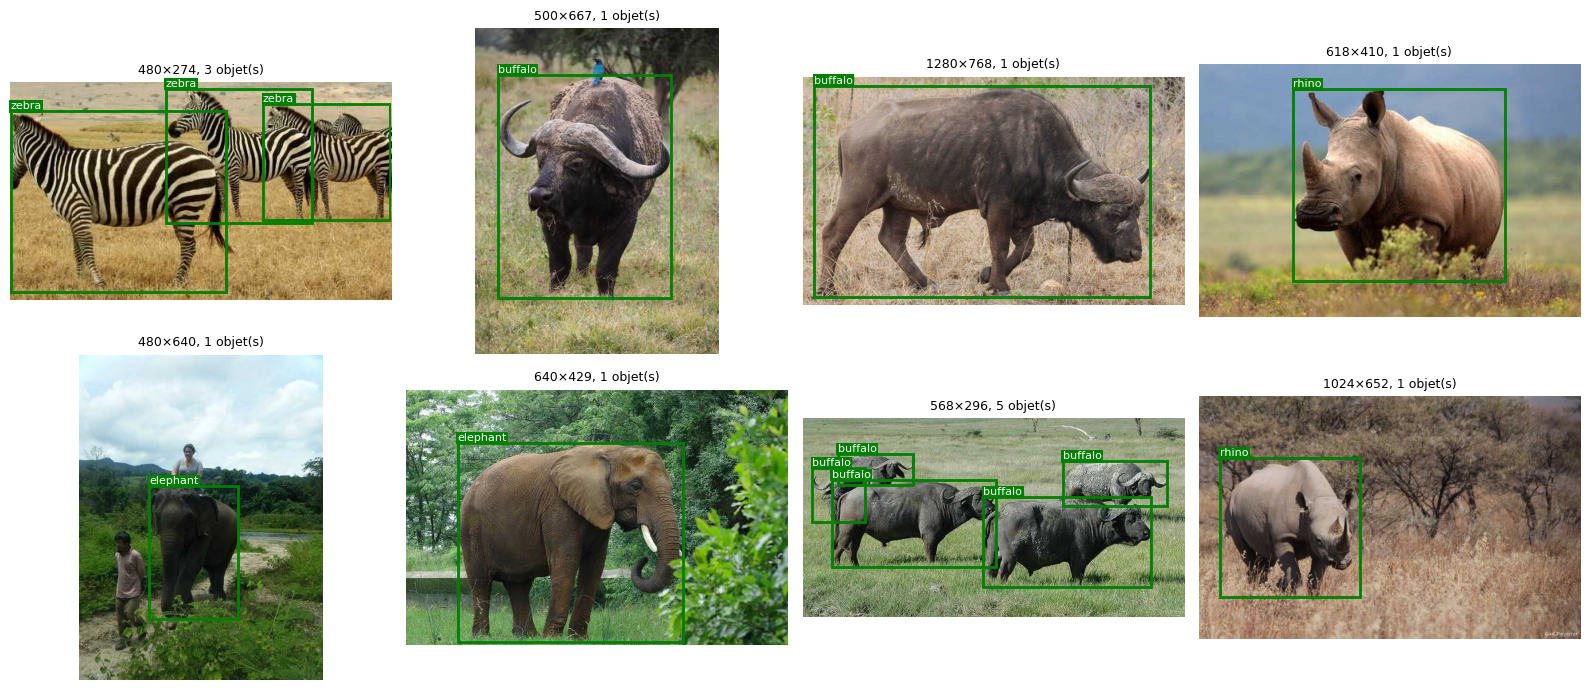

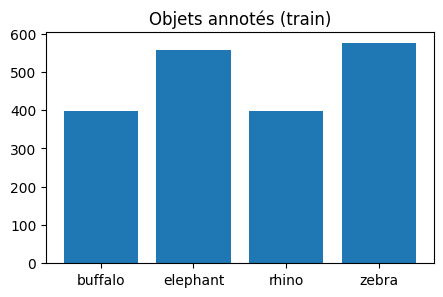

In [33]:
def dessiner(ax, img, boxes, cls, couleur, scores=None, style="-"):
    ax.imshow(img); ax.axis("off")
    for k, (x1, y1, x2, y2) in enumerate(boxes):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, ec=couleur, lw=2, ls=style))
        txt = noms[int(cls[k])] + ("" if scores is None else f" {scores[k]:.2f}")
        ax.text(x1, y1, txt, color="white", fontsize=8, va="bottom", bbox=dict(fc=couleur, ec="none", pad=1))

rng = np.random.default_rng(0)
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
for a, p in zip(ax.flat, rng.choice(images["train"], 8, replace=False)):
    img = np.array(Image.open(p).convert("RGB"))
    cls, b = lire_labels(p)
    dessiner(a, img, xywhn_vers_xyxy(b, img.shape[1], img.shape[0]), cls, "green")
    a.set_title(f"{img.shape[1]}×{img.shape[0]}, {len(cls)} objet(s)", fontsize=9)
plt.tight_layout(); plt.show()

# Répartition des classes (en nombre d'objets, pas d'images)
compte = np.bincount(np.concatenate([lire_labels(p)[0] for p in images["train"]]), minlength=len(noms))
plt.figure(figsize=(5, 3)); plt.bar(list(noms.values()), compte); plt.title("Objets annotés (train)"); plt.show()

**Question 6 :** Que faut-il annoter en plus par rapport à la classification ? Estimez le temps d'annotation d'une image avec 3 animaux, par rapport à une simple étiquette. Pourquoi les coordonnées sont-elles **normalisées** plutôt qu'en pixels ?

**6.** Il faut tracer une boîte et attribuer une classe pour chaque instance. Pour trois animaux bien visibles, on peut estimer 20 à 60 secondes contre 1 à 5 secondes pour une étiquette simple. Le temps augmente avec les occultations et les contrôles. Diviser les coordonnées horizontales par la largeur et les verticales par la hauteur les rend relatives à l'image et invariantes à un redimensionnement sans recadrage ni ajout de bordure.

## 5. Fine-tuning

Comme au TP6, on part d'un modèle **pré-entraîné** (sur COCO) et on l'adapte. La couche de sortie passe de 80 à 4 classes ; Ultralytics recopie automatiquement tous les poids compatibles.

On compare deux stratégies, avec le **même nombre d'époques** :
- **backbone gelé** (`freeze=10`) : les 10 premiers modules (l'extracteur de caractéristiques) ne bougent pas, c'est l'équivalent de l'extraction de caractéristiques du TP6 ;
- **réseau complet** : tous les poids sont réentraînés.

Ultralytics gère l'optimiseur, le taux d'apprentissage, l'augmentation de données et la validation à chaque époque. Les résultats sont enregistrés dans `runs/detect/<nom>/`.

In [34]:
EPOCHS, IMGSZ = 15, 640
cfg = dict(data=DATA, epochs=EPOCHS, imgsz=IMGSZ, batch=16, seed=0, exist_ok=True, workers=0, plots=True, device=0 if torch.cuda.is_available() else "cpu")

t0 = time.time()
model_gele = YOLO("yolo11n.pt")
res_gele = model_gele.train(name="gele", freeze=10, **cfg)
t_gele = time.time() - t0

t0 = time.time()
model_complet = YOLO("yolo11n.pt")
res_complet = model_complet.train(name="complet", **cfg)
t_complet = time.time() - t0

print(f"Temps / époque : gelé {t_gele / EPOCHS:.0f} s | complet {t_complet / EPOCHS:.0f} s")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=gele, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, o

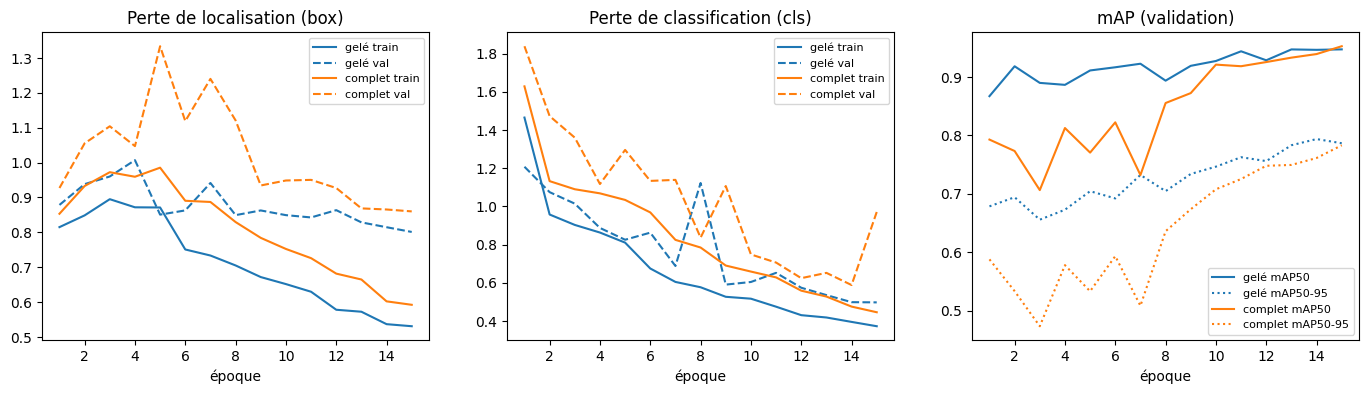

In [35]:
def courbes(**runs):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    for (nom, dossier), c in zip(runs.items(), ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
        df = pd.read_csv(Path(dossier) / "results.csv")
        df.columns = df.columns.str.strip()
        ax[0].plot(df["epoch"], df["train/box_loss"], c=c, label=f"{nom} train")
        ax[0].plot(df["epoch"], df["val/box_loss"], "--", c=c, label=f"{nom} val")
        ax[1].plot(df["epoch"], df["train/cls_loss"], c=c, label=f"{nom} train")
        ax[1].plot(df["epoch"], df["val/cls_loss"], "--", c=c, label=f"{nom} val")
        ax[2].plot(df["epoch"], df["metrics/mAP50(B)"], c=c, label=f"{nom} mAP50")
        ax[2].plot(df["epoch"], df["metrics/mAP50-95(B)"], ":", c=c, label=f"{nom} mAP50-95")
    for a, t in zip(ax, ["Perte de localisation (box)", "Perte de classification (cls)", "mAP (validation)"]):
        a.set_title(t); a.set_xlabel("époque"); a.legend(fontsize=8)
    plt.show()

courbes(gelé=res_gele.save_dir, complet=res_complet.save_dir)

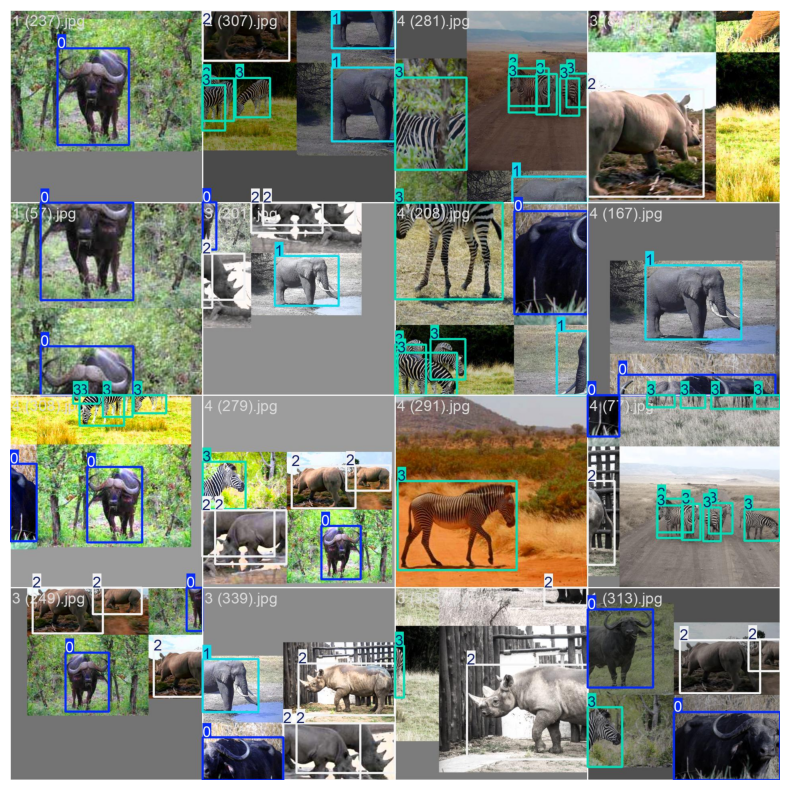

In [36]:
# Un lot d'entraînement tel que le réseau le voit (après augmentation)
plt.figure(figsize=(10, 10))
plt.imshow(plt.imread(Path(res_complet.save_dir) / "train_batch0.jpg")); plt.axis("off"); plt.show()

**Question 7 :** Comparez les deux stratégies : mAP aux **premières** époques, mAP **final**, temps par époque, écart train/validation. Laquelle démarre le plus vite ? Laquelle finit le mieux ? Expliquez (pensez au nombre de paramètres modifiés et au lien avec le TP6).
Dans les journaux, repérez la ligne `Remapped 2/4 cls head rows from pretrained weights by class name` : quelles sont ces 2 classes, et pourquoi peut-on réutiliser leurs poids de sortie COCO ?

**Question 8 :** La perte de YOLO est une somme de trois termes : `box_loss`, `cls_loss` et `dfl_loss`. À quoi correspond chacun (cherchez *Distribution Focal Loss* pour le dernier) ? Pourquoi la perte d'un détecteur combine-t-elle **localisation** et **classification** ?

**Question 9 :** Observez le lot d'entraînement ci-dessus. Quelle augmentation reconnaissez-vous (*mosaic*) ? Pourquoi est-elle utile pour la détection ? Pourquoi Ultralytics la désactive-t-il pendant les dernières époques (`close_mosaic`) ?

**7.** La cellule suivante compare les premières époques, la dernière et les temps mesurés. Geler le backbone réduit le nombre de poids à adapter et peut accélérer chaque époque. Le réseau complet peut mieux s'adapter au nouveau domaine, au prix d'un calcul et d'un risque de surapprentissage accrus. Une perte d'entraînement qui baisse pendant que la perte de validation remonte est un indice à vérifier sur les courbes. Cette comparaison reprend les stratégies d'extraction de caractéristiques et de fine-tuning du TP6. Les deux noms en commun sont **elephant** et **zebra**. Si la version installée remappe la tête par nom et que ses dimensions sont compatibles, elle peut transférer les lignes COCO correspondantes. La présence du message de remappage dépend de la version.

**8.** La perte de boîte mesure la qualité géométrique de la prédiction (via la CIoU pour YOLO11). La perte de classification ajuste les scores de classe. La Distribution Focal Loss entraîne une distribution discrète pour chacune des quatre distances aux bords. Les deux valeurs discrètes qui encadrent la cible reçoivent des poids selon leur distance à celle-ci. Une bonne détection suppose à la fois une boîte correctement placée et une classe correcte. [Article Generalized Focal Loss](https://proceedings.neurips.cc/paper/2020/hash/f0bda020d2470f2e74990a07a607ebd9-Abstract.html)

**9.** Mosaic assemble des portions de quatre images dans une même image. Il diversifie les scènes, les tailles et les positions des objets. Sa désactivation en fin d'entraînement rapproche les images d'entraînement des scènes ordinaires utilisées en validation et en production.

In [37]:
from IPython.display import display

comparaison = {}
for nom, run, duree in [("gelé", res_gele, t_gele), ("complet", res_complet, t_complet)]:
    df = pd.read_csv(Path(run.save_dir) / "results.csv")
    df.columns = df.columns.str.strip()
    comparaison[nom] = {
        "mAP50 début": df["metrics/mAP50(B)"].head(3).mean(),
        "mAP50-95 début": df["metrics/mAP50-95(B)"].head(3).mean(),
        "mAP50 finale": df["metrics/mAP50(B)"].iloc[-1],
        "mAP50-95 finale": df["metrics/mAP50-95(B)"].iloc[-1],
        "secondes / époque": duree / len(df),
        "écart box val − train (fin)": (df["val/box_loss"] - df["train/box_loss"]).tail(3).mean(),
        "écart cls val − train (fin)": (df["val/cls_loss"] - df["train/cls_loss"]).tail(3).mean(),
    }
comparaison = pd.DataFrame(comparaison).T
display(comparaison.round(4))
for col in ("mAP50-95 début", "mAP50-95 finale"):
    print(f"{col} : {', '.join(comparaison.index[comparaison[col] == comparaison[col].max()])}")
print("Classes en commun :", sorted(set(model.names.values()) & set(noms.values())))

,mAP50 début,mAP50-95 début,mAP50 finale,mAP50-95 finale,secondes / époque,écart box val − train (fin),écart cls val − train (fin)
gelé,0.8919,0.6761,0.9474,0.7866,21.5334,0.2681,0.1151
complet,0.7575,0.5314,0.9528,0.7831,23.1409,0.2450,0.2538


mAP50-95 début : gelé
mAP50-95 finale : gelé
Classes en commun : ['elephant', 'zebra']


## 6. Évaluation sur le jeu de test

En détection, l'« accuracy » n'a pas de sens. On apparie chaque prédiction à une boîte réelle de même classe (IoU ≥ seuil), puis :
- **Précision** = vrais positifs / prédictions : *parmi ce que le modèle détecte, quelle part est correcte ?*
- **Rappel** = vrais positifs / objets réels : *parmi les objets présents, quelle part est trouvée ?*
- **AP** (*Average Precision*) = aire sous la courbe précision-rappel, obtenue en faisant varier le seuil de confiance ;
- **mAP** = moyenne des AP sur les classes. **mAP50** utilise IoU ≥ 0,5 ; **mAP50-95** fait la moyenne sur les seuils d'IoU de 0,5 à 0,95.

In [20]:
resultats = {}
for nom, r in [("gele", res_gele), ("complet", res_complet)]:
    mdl = YOLO(Path(r.save_dir) / "weights" / "best.pt")
    m = mdl.val(data=DATA, split="test", imgsz=IMGSZ, name=f"test_{nom}", exist_ok=True, verbose=False, device=cfg["device"], batch=cfg["batch"], plots=True)
    resultats[nom] = (mdl, m)
    print(f"{nom:8s} précision {m.box.mp:.3f} | rappel {m.box.mr:.3f} | mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")

def lire_resultats(r):
    df = pd.read_csv(Path(r.save_dir) / "results.csv")
    df.columns = df.columns.str.strip()
    return df

validations = {"gele": lire_resultats(res_gele), "complet": lire_resultats(res_complet)}
nom_best = max(validations, key=lambda k: validations[k]["metrics/mAP50-95(B)"].max())
best, m = resultats[nom_best]
print(f"\nModèle retenu selon la validation : {nom_best}")
print("mAP50-95 par classe :", {noms[i]: round(float(v), 3) for i, v in enumerate(m.box.maps)})

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2026.0±1443.6 MB/s, size: 106.3 KB)
val: Scanning /content/datasets/african-wildlife/labels/test.cache... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 68.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 5.2it/s 2.9s
                   all        227        375      0.961      0.902      0.966       0.82
Speed: 1.0ms preprocess, 3.8ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/test_gele
gele     précision 0.961 | rappel 0.902 | mAP50 0.966 | mAP50-95 0.820
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,780 parameters, 0 gradients, 6.4 GFLOPs
val: Fast imag

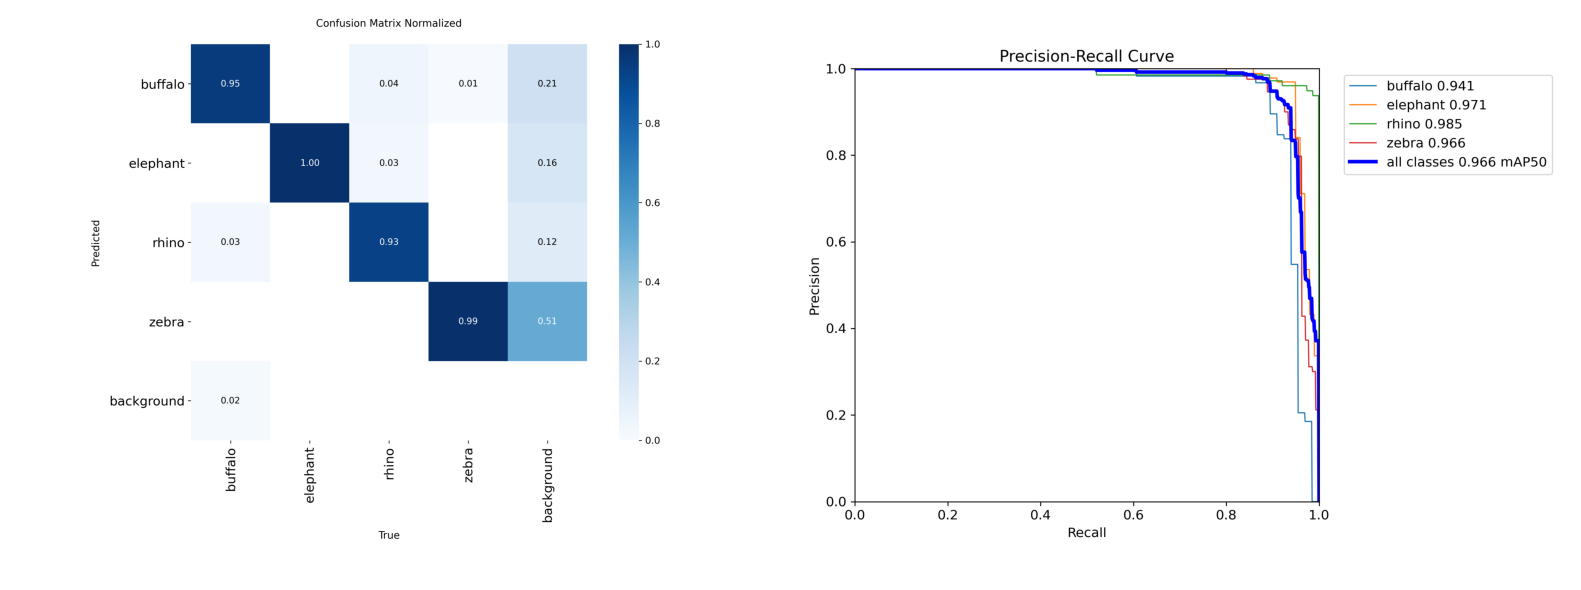

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for a, f in zip(ax, ["confusion_matrix_normalized.png", "BoxPR_curve.png"]):
    a.imshow(plt.imread(Path(m.save_dir) / f)); a.axis("off")
plt.tight_layout(); plt.show()

**Question 10 :** Pourquoi résumer un détecteur par l'**aire** sous la courbe précision-rappel plutôt que par la précision à un seul seuil de confiance ? La matrice de confusion a une ligne et une colonne supplémentaires, `background` : à quels types d'erreurs correspondent-elles ? Quelle classe est la plus difficile, et pourquoi selon vous ?

**10.** L'AP résume le compromis précision–rappel sur différents seuils de confiance. Dans la matrice Ultralytics (prédictions en lignes, vérité terrain en colonnes), la ligne background représente les objets manqués et la colonne background les détections sans objet apparié. Une confusion de classe appariée apparaît hors diagonale. La classe au plus faible AP moyen est affichée ci-dessous. Les effectifs et la matrice permettent d'examiner l'hypothèse d'une classe peu représentée ou souvent confondue. Les exemples d'erreurs permettent de rechercher l'effet de la taille et de l'occultation.

In [42]:
display(
    pd.DataFrame({"AP50-95 test": ap, "Objets annotés (train)": effectifs})
    .sort_values("AP50-95 test")
)

,AP50-95 test,Objets annotés (train)
zebra,0.765027,575
elephant,0.785330,557
buffalo,0.844577,398
rhino,0.885680,398


## 7. Analyse des erreurs

On compte, pour chaque image de test, les **faux positifs** (prédiction sans boîte réelle correspondante) et les **faux négatifs** (objet réel manqué), puis on affiche les images les plus problématiques.
Vérité terrain en **vert pointillé**, prédictions en **rouge**.

Total faux positifs : 35 | faux négatifs : 19


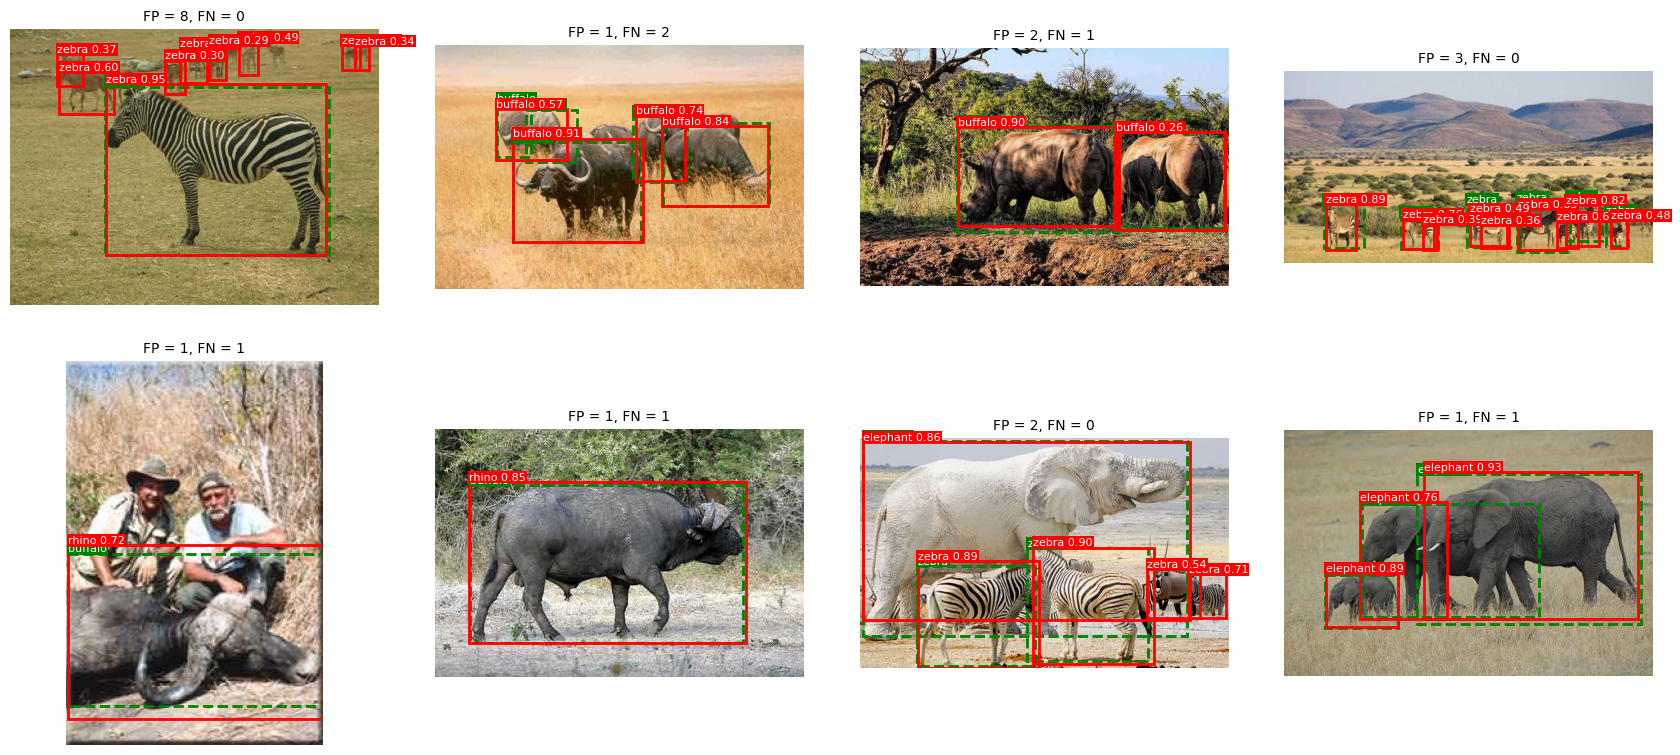

In [43]:
def apparier(gt_b, gt_c, pr_b, pr_c, seuil=0.5):
    # Appariement glouton (prédictions triées par confiance décroissante) -> (nb faux positifs, nb faux négatifs)
    libre = np.ones(len(gt_b), bool)
    fp = 0
    for b, c in zip(pr_b, pr_c):
        cand = np.where(libre & (gt_c == c))[0]
        if len(cand) and iou(b, gt_b[cand]).max() >= seuil:
            libre[cand[iou(b, gt_b[cand]).argmax()]] = False
        else:
            fp += 1
    return fp, int(libre.sum())

bilan = []
for p, r in zip(images["test"], best.predict(images["test"], imgsz=IMGSZ, stream=True, verbose=False)):
    h, w = r.orig_shape
    gt_c, gt = lire_labels(p)
    gt_b = xywhn_vers_xyxy(gt, w, h)
    pr_b, pr_c, pr_s = r.boxes.xyxy.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int), r.boxes.conf.cpu().numpy()
    fp, fn = apparier(gt_b, gt_c, pr_b, pr_c)
    bilan.append((fp + fn, fp, fn, p, gt_b, gt_c, pr_b, pr_c, pr_s))

print("Total faux positifs :", sum(x[1] for x in bilan), "| faux négatifs :", sum(x[2] for x in bilan))
pires = sorted(bilan, key=lambda x: -x[0])[:8]
fig, ax = plt.subplots(2, 4, figsize=(17, 8))
for a, (_, fp, fn, p, gt_b, gt_c, pr_b, pr_c, pr_s) in zip(ax.flat, pires):
    img = np.array(Image.open(p).convert("RGB"))
    dessiner(a, img, gt_b, gt_c, "green", style="--")
    dessiner(a, img, pr_b, pr_c, "red", scores=pr_s)
    a.set_title(f"FP = {fp}, FN = {fn}", fontsize=10)
plt.tight_layout(); plt.show()

**Question 11 :** Classez les erreurs observées : mauvaise classe, boîte mal placée, doublon, objet manqué (petit, caché, coupé par le bord), fausse alarme sur le fond. Certaines erreurs viennent-elles en fait d'**annotations** fausses ou incomplètes ?

**11.** Deux cas réels sont détaillés automatiquement sous cette réponse à partir des prédictions et des annotations. Une boîte rouge qui entoure un animal reconnaissable sans boîte verte correspondante est un candidat à une annotation manquante. Une boîte verte décalée ou une classe verte incohérente mérite également une vérification visuelle. Le seul appariement ne suffit pas à confirmer une erreur dans les annotations.

In [44]:
def commenter_erreurs(cas):
    _, fp, fn, p, gt_b, gt_c, pr_b, pr_c, pr_s = cas
    libres = np.ones(len(gt_b), dtype=bool)
    print(f"{p.name} — {fp} faux positif(s), {fn} faux négatif(s)")
    for b, c, score in zip(pr_b, pr_c, pr_s):
        chevauchements = iou(b, gt_b)
        meme_classe = gt_c == c
        indices = np.flatnonzero(libres & meme_classe & (chevauchements >= 0.5))
        if indices.size:
            libres[indices[chevauchements[indices].argmax()]] = False
            continue
        if np.any(meme_classe & (chevauchements >= 0.5)):
            cause = "doublon probable"
        elif np.any(chevauchements >= 0.5):
            cible = chevauchements.argmax()
            cause = f"confusion probable avec {noms[gt_c[cible]]}"
        elif np.any(meme_classe & (chevauchements >= 0.1)):
            cause = "localisation insuffisante possible"
        else:
            cause = "fausse alarme ou objet non annoté à vérifier"
        print(f"  FP {noms[c]} ({score:.2f}) : {cause} ; IoU max {chevauchements.max(initial=0):.2f}")
    for b, c in zip(gt_b[libres], gt_c[libres]):
        w, h = b[2:] - b[:2]
        print(f"  FN {noms[c]} : annotation sans prédiction valide, boîte {w:.0f} × {h:.0f} px")

for cas in [cas for cas in pires if cas[0] > 0][:2]:
    commenter_erreurs(cas)

4 (200).jpg — 8 faux positif(s), 0 faux négatif(s)
  FP zebra (0.60) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.01
  FP zebra (0.59) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.00
  FP zebra (0.49) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.00
  FP zebra (0.44) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.00
  FP zebra (0.37) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.00
  FP zebra (0.34) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.00
  FP zebra (0.30) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.00
  FP zebra (0.29) : fausse alarme ou objet non annoté à vérifier ; IoU max 0.00
1 (376).jpg — 1 faux positif(s), 2 faux négatif(s)
  FP buffalo (0.57) : localisation insuffisante possible ; IoU max 0.48
  FN buffalo : annotation sans prédiction valide, boîte 140 × 145 px
  FN buffalo : annotation sans prédiction valide, boîte 94 × 148 px


## 8. Hors du domaine d'entraînement

YOLO11n COCO [('bus', 0.94), ('person', 0.888), ('person', 0.878), ('person', 0.856), ('person', 0.622)]
YOLO11n fine-tuné []


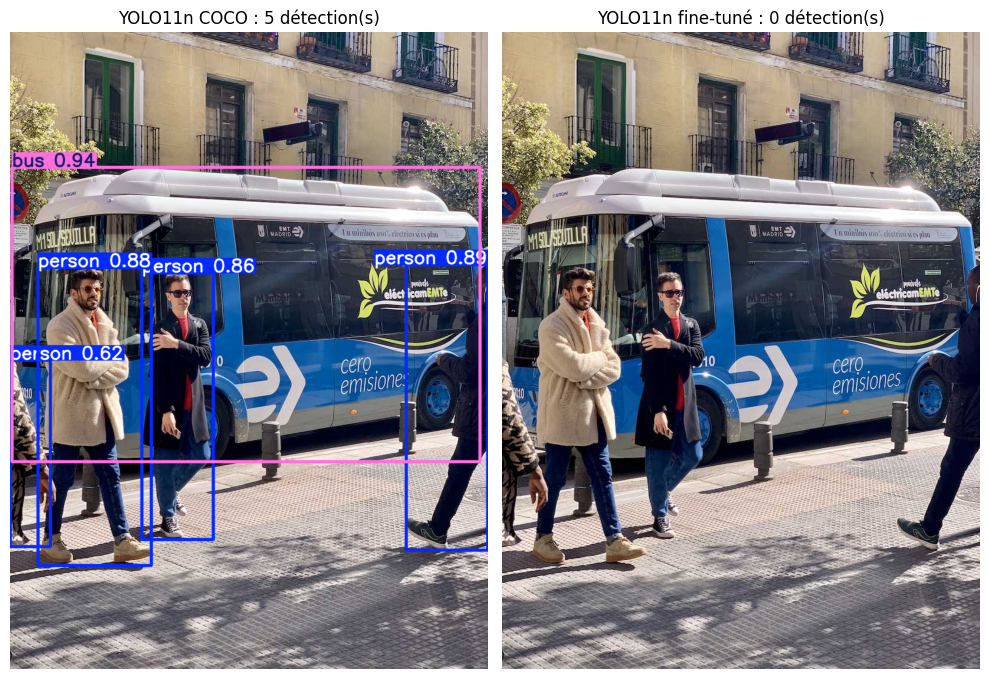

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(10, 7))
for a, (titre, mdl) in zip(ax, [("YOLO11n COCO", model), ("YOLO11n fine-tuné", best)]):
    r = mdl(ASSETS / "bus.jpg", verbose=False)[0]
    a.imshow(r.plot()[..., ::-1]); a.axis("off"); a.set_title(f"{titre} : {len(r.boxes)} détection(s)")
    print(titre, [(mdl.names[int(c)], round(float(s), 3)) for c, s in zip(r.boxes.cls, r.boxes.conf)])
plt.tight_layout(); plt.show()

In [ ]:
from torch.hub import download_url_to_file

chien = Path("chien_tp7.jpg")
if not chien.exists():
    download_url_to_file("https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg", str(chien))
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (titre, source) in zip(axes, [("Chien hors vocabulaire", chien), ("Scène sans animal", ASSETS / "bus.jpg")]):
    r = best(source, conf=0.25, imgsz=IMGSZ, verbose=False)[0]
    print(titre, [(best.names[int(c)], round(float(s), 3)) for c, s in zip(r.boxes.cls, r.boxes.conf)])
    ax.imshow(r.plot()[..., ::-1])
    ax.set_title(f"{titre} ({len(r.boxes)} détection(s))")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Question 12 :** Le modèle fine-tuné détecte-t-il encore les personnes et le bus ? Que détecte-t-il à la place, et pourquoi ? Comment s'appelle ce phénomène ? Comment pourrait-on garder les 80 classes de COCO **et** ajouter les 4 nouvelles ?

**Question 13 :** Donnez au modèle une photo d'un animal **absent** des classes (lion, vache, chien), puis une photo sans animal. Que se passe-t-il ? Contrairement à la softmax du TP6, YOLO utilise une sigmoïde indépendante par classe : pourquoi cela lui permet-il de répondre « rien » ? Cela suffit-il à éviter les fausses détections ?

**12.** Après adaptation, la tête ne contient plus que quatre catégories animales. Sur le bus, une prédiction éventuelle appartient donc à l'une de ces quatre classes et constitue une fausse détection hors domaine. La disparition des sorties COCO résulte ici directement du remplacement de la tête, dans un contexte de perte de capacités lors du transfert souvent appelé oubli catastrophique. Pour les préserver, entraîner une tête sur l'union des vocabulaires et mélanger des exemples annotés des deux domaines. L'éléphant et le zèbre figurent déjà dans COCO, donc l'union compte **82 classes distinctes**.

**13.** Un chien est hors vocabulaire et peut être ignoré ou pris pour l'un des quatre animaux. Une scène sans animal peut produire zéro boîte ou une fausse alarme. Les sigmoïdes permettent à tous les scores d'être faibles simultanément, puis le seuil peut écarter tous les candidats. Cette possibilité ne garantit pas des scores faibles sur une image hors distribution. La cellule précédente donne les observations sur les deux images utilisées.

## 9. Exercices

### Exercice A : Taille du modèle et compromis vitesse / précision
Refaites le fine-tuning complet (partie 5, mêmes réglages) avec **YOLO11s** et **YOLO11m**, puis avec **YOLO26n** (`yolo26n.pt`), une version plus récente. Mesurez le temps d'inférence par image sur le jeu de test (`m.speed["inference"]` après `val`).

| Modèle | Nb paramètres | GFLOPs | Temps / époque | Inférence (ms/image) | mAP50 test | mAP50-95 test |
|---|---|---|---|---|---|---|
| YOLO11n | | | | | | |
| YOLO11s | | | | | | |
| YOLO11m | | | | | | |
| YOLO26n | | | | | | |

Tracez la mAP50-95 en fonction du temps d'inférence. Quel modèle choisiriez-vous pour une caméra embarquée sur un drone ? Pour une analyse d'images *a posteriori* ?
YOLO26 est annoncé « sans NMS » (*end-to-end*). Vérifiez-le en comparant `yolo26n.pt` avec `iou=0.7` et `iou=1.0` sur `bus.jpg`. Quel est l'intérêt pour le déploiement ?

### Exercice B : Avec très peu de données
Entraînez avec seulement **10 % du jeu d'entraînement** (argument `fraction=0.1`, environ 100 images), 30 époques :
1. YOLO11n **from scratch** : `YOLO("yolo11n.yaml")` (architecture seule, poids aléatoires) ;
2. YOLO11n **pré-entraîné** : `YOLO("yolo11n.pt")`.

Comparez les mAP de test. Refaites l'expérience avec 100 % des données. L'écart se réduit-il ? Conclusion ?

### Exercice C (bonus) : Suivi d'objets dans une vidéo
Sur une courte vidéo de rue, utilisez `model.track(source="video.mp4", tracker="bytetrack.yaml", save=True)` avec le modèle COCO. Chaque objet reçoit un **identifiant** stable d'une image à l'autre (`r.boxes.id`). Comptez le nombre de **personnes différentes** vues dans la vidéo. Pourquoi ne peut-on pas simplement additionner les détections de chaque image ?

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s_complet, nbs=64, nms=None, opset=None, optimize=False, opti

,Paramètres,GFLOPs,s/époque,ms/image,mAP50 test,mAP50-95 test
Modèle,,,,,,
YOLO11n,2605612,6.5712,23.1409,3.3461,0.9712,0.8108
YOLO11s,9429340,21.6729,28.7527,7.1731,0.9644,0.8032
YOLO11m,20056092,68.3162,54.2236,20.3826,0.9614,0.7787
YOLO26n,2535344,6.0354,24.7111,3.6197,0.9789,0.8306


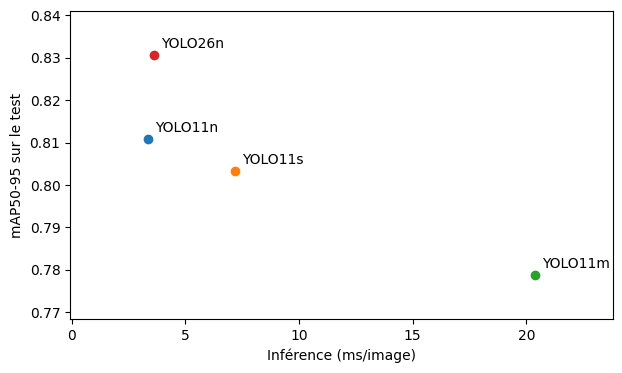

Drone, priorité à la latence mesurée : YOLO11n
Analyse hors ligne, priorité à la mAP : YOLO26n


In [46]:
# Exercice A — modèles adaptés avec le même protocole
def entrainer(poids, nom, **options):
    mdl = YOLO(poids)
    debut = time.perf_counter()
    run = mdl.train(**(cfg | dict(name=nom) | options))
    duree = time.perf_counter() - debut
    repetitions = len(lire_resultats(run))
    mdl = YOLO(Path(run.save_dir) / "weights" / "best.pt")
    metriques = mdl.val(data=DATA, split="test", imgsz=IMGSZ, batch=cfg["batch"],
                        device=cfg["device"], plots=True, name=f"test_{nom}", exist_ok=True)
    return mdl, metriques, duree / repetitions

essais_a = {"YOLO11n": (*resultats["complet"], t_complet / len(validations["complet"]))}
for nom, fichier in [("YOLO11s", "yolo11s.pt"), ("YOLO11m", "yolo11m.pt"), ("YOLO26n", "yolo26n.pt")]:
    essais_a[nom] = entrainer(fichier, nom.lower() + "_complet")

lignes_a = []
for nom, (mdl, mesures_test, temps) in essais_a.items():
    _, params, _, flops = mdl.info(imgsz=IMGSZ)
    lignes_a.append([nom, params, flops, temps, mesures_test.speed["inference"],
                     mesures_test.box.map50, mesures_test.box.map])
table_a = pd.DataFrame(lignes_a, columns=["Modèle", "Paramètres", "GFLOPs", "s/époque",
                                         "ms/image", "mAP50 test", "mAP50-95 test"]).set_index("Modèle")
display(table_a.round(4))
fig, ax = plt.subplots(figsize=(7, 4))
for nom, ligne in table_a.iterrows():
    x, y = ligne["ms/image"], ligne["mAP50-95 test"]
    ax.scatter(x, y)
    ax.annotate(nom, (x, y), xytext=(5, 5), textcoords="offset points")
ax.set(xlabel="Inférence (ms/image)", ylabel="mAP50-95 sur le test")
ax.margins(0.2)
plt.show()
print("Drone, priorité à la latence mesurée :", table_a["ms/image"].idxmin())
print("Analyse hors ligne, priorité à la mAP :", table_a["mAP50-95 test"].idxmax())

Pour un drone, le modèle le plus rapide du tableau est le premier candidat si sa mAP répond au besoin. La latence, la mémoire et la consommation doivent être vérifiées sur le matériel embarqué. Pour un traitement hors ligne, le meilleur score mAP50–95 est le critère principal ici. Le mode end-to-end de YOLO26 simplifie l'export et le post-traitement en supprimant l'étape de NMS classique. [Documentation YOLO26](https://docs.ultralytics.com/models/yolo26/)

In [50]:
modele26 = YOLO("yolo26n.pt")

predictions26 = [
    modele26.predict(
        ASSETS / "bus.jpg",
        end2end=True,
        conf=0.25,
        iou=seuil,
        verbose=False,
    )[0].boxes.data.cpu().numpy()
    for seuil in (0.7, 1.0)
]

p07, p10 = predictions26
print("Mode end-to-end :", getattr(modele26.model, "end2end", None))
print(f"Nombre de détections — iou=0.7 : {len(p07)}, iou=1.0 : {len(p10)}")

identiques = p07.shape == p10.shape and np.allclose(p07, p10, atol=1e-4, rtol=0)
print("Mêmes boîtes, scores et classes :", identiques)

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.
WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.
Mode end-to-end : False
Nombre de détections — iou=0.7 : 5, iou=1.0 : 5
Mêmes boîtes, scores et classes : True


In [51]:
# Exercice B — quatre entraînements de 30 époques
lignes_b = []
for fraction in (0.1, 1.0):
    for init, poids in [("aléatoire", "yolo11n.yaml"), ("COCO", "yolo11n.pt")]:
        mode = "coco" if init == "COCO" else "scratch"
        nom = f"donnees_{int(100 * fraction)}_{mode}"
        _, metriques, _ = entrainer(poids, nom, epochs=30, fraction=fraction, pretrained=(init == "COCO"))
        lignes_b.append([int(100 * fraction), init, metriques.box.map50, metriques.box.map])
table_b = pd.DataFrame(lignes_b, columns=["Données (%)", "Initialisation", "mAP50 test", "mAP50-95 test"])
display(table_b.round(4))
for indicateur in ("mAP50 test", "mAP50-95 test"):
    pivot = table_b.pivot(index="Données (%)", columns="Initialisation", values=indicateur)
    gains = pivot["COCO"] - pivot["aléatoire"]
    print(f"{indicateur} : gain signé du pré-entraînement {gains.loc[10]:+.3f} à 10 % et {gains.loc[100]:+.3f} à 100 %")
    ecart = gains.abs()
    relation = "diminue" if ecart.loc[100] < ecart.loc[10] else "augmente" if ecart.loc[100] > ecart.loc[10] else "reste stable"
    print(f"L'écart absolu {relation} avec toutes les données.")

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=donnees_10_scratch, nbs=64, nms=None, opset=None, optimize=False,

,Données (%),Initialisation,mAP50 test,mAP50-95 test
0,10,aléatoire,0.0759,0.0283
1,10,COCO,0.5881,0.4971
2,100,aléatoire,0.8107,0.5624
3,100,COCO,0.9736,0.8228


mAP50 test : gain signé du pré-entraînement +0.512 à 10 % et +0.163 à 100 %
L'écart absolu diminue avec toutes les données.
mAP50-95 test : gain signé du pré-entraînement +0.469 à 10 % et +0.260 à 100 %
L'écart absolu diminue avec toutes les données.


Le pré-entraînement fournit des caractéristiques visuelles disponibles avant de voir les premières images du TP. On s'attend à ce que cette initialisation aide particulièrement à 10 %. Avec davantage de données, un modèle aléatoire peut apprendre de meilleures représentations. Le tableau permet de vérifier si l'écart diminue sur ce jeu et à budget égal de 30 époques.

In [52]:
# Exercice C (bonus) — placer une courte vidéo de rue sous le nom video.mp4
video = Path("video.mp4")
if video.is_file():
    personnes = set()
    for r in model.track(source=str(video), tracker="bytetrack.yaml", stream=True,
                         save=True, classes=[0], verbose=False):
        if r.boxes.id is not None:
            personnes.update(r.boxes.id.int().cpu().tolist())
    print(f"Nombre de pistes de personnes distinctes : {len(personnes)}")
else:
    print("Ajouter video.mp4 pour effectuer le suivi.")

Ajouter video.mp4 pour effectuer le suivi.


Additionner les détections image par image recompterait chaque personne visible sur plusieurs images. ByteTrack maintient un identifiant de piste au fil des images. Ce décompte reste une estimation, car une occultation peut scinder une piste et un changement d'identifiant peut fausser le total.

## 10. Compte rendu attendu
- Réponses aux questions 1 à 13
- Fonction `nms` complétée et validée
- Courbes d'entraînement (gelé vs complet), matrice de confusion, courbe précision-rappel
- 2 exemples d'erreurs commentés (partie 7)
- Tableau de l'exercice A et conclusion de l'exercice B

---
*Ordres de grandeur (mesurés en images 320 px, à titre indicatif) : dès 2 époques de fine-tuning, mAP50 test ≈ 0,8–0,9. Exercice B (10 % des données, 30 époques) : from scratch mAP50 ≈ 0,05, pré-entraîné ≈ 0,45. Attendez-vous à des valeurs un peu plus élevées en 640 px.*